In [2]:

# ============================================================
# CELDA 1. CONFIGURACIÓN INICIAL DEL PROYECTO
# ============================================================

# Importamos las librerías necesarias para descargar,
# procesar y guardar los datos históricos de vuelos BTS.

import pandas as pd
import numpy as np
import requests
import zipfile
import time

from pathlib import Path
from google.colab import drive
from IPython.display import display

# Conectamos Google Drive para conservar los archivos.
# Así no perderemos el trabajo si Colab se desconecta.
drive.mount("/content/drive")

# Definimos una carpeta principal para nuestro proyecto.
BASE = Path("/content/drive/MyDrive/flight_delay_bigdata")

# RAW: archivos ZIP originales descargados de BTS.
# SAMPLE: muestras mensuales y dataset final para EDA.
RAW = BASE / "raw_bts"
SAMPLE = BASE / "sample"

RAW.mkdir(parents=True, exist_ok=True)
SAMPLE.mkdir(parents=True, exist_ok=True)

# Analizaremos enero-diciembre de 2024 y 2025.
periodos_descarga = [
    (anio, mes)
    for anio in [2024, 2025]
    for mes in range(1, 13)
]

# Seleccionaremos 5,000 vuelos por mes.
# Usamos una semilla fija para reproducir el muestreo.
N_MUESTRA_MES = 5000
SEMILLA = 42

print("Proyecto configurado correctamente.")
print("Carpeta principal:", BASE)
print("Meses a procesar:", len(periodos_descarga))
print("Vuelos por mes:", N_MUESTRA_MES)
print("Muestra esperada:", len(periodos_descarga) * N_MUESTRA_MES)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto configurado correctamente.
Carpeta principal: /content/drive/MyDrive/flight_delay_bigdata
Meses a procesar: 24
Vuelos por mes: 5000
Muestra esperada: 120000


In [4]:

# ============================================================
# CELDA 2. DESCARGA BTS Y MUESTREO MENSUAL 2024-2025
# ============================================================

# Descargamos los archivos de la fuente oficial BTS.
# Por cada mes seleccionamos 5,000 vuelos aleatorios.
#
# Para reducir el uso de memoria, leemos el CSV por bloques
# y conservamos los registros con menores números aleatorios.
# Esto permite generar una muestra sin cargar todo el mes en RAM.

errores = []
resumen_descarga = []

def descargar_zip(url, destino, intentos=3):

    # Si el ZIP ya existe y es válido, lo reutilizamos.
    if destino.exists():
        if zipfile.is_zipfile(destino):
            return
        else:
            destino.unlink()

    # Guardamos primero en un archivo temporal para evitar
    # confundir una descarga incompleta con una válida.
    temporal = destino.with_suffix(".part")

    for intento in range(1, intentos + 1):
        try:
            with requests.get(
                url,
                stream=True,
                timeout=(30, 180)
            ) as respuesta:

                respuesta.raise_for_status()

                with open(temporal, "wb") as archivo:
                    for bloque in respuesta.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if bloque:
                            archivo.write(bloque)

            if not zipfile.is_zipfile(temporal):
                raise ValueError("El archivo descargado no es un ZIP válido.")

            temporal.replace(destino)
            return

        except Exception as error:
            temporal.unlink(missing_ok=True)

            if intento == intentos:
                raise error

            print(f"Reintentando descarga ({intento}/{intentos})...")
            time.sleep(5)


def muestrear_zip(ruta_zip, anio, mes, n_muestra=5000):

    # Generamos una semilla diferente para cada mes,
    # pero reproducible si volvemos a correr el notebook.
    rng = np.random.default_rng(
        SEMILLA + anio * 100 + mes
    )

    candidatos = None
    total_filas = 0

    with zipfile.ZipFile(ruta_zip) as comprimido:

        csvs = [
            nombre
            for nombre in comprimido.namelist()
            if nombre.lower().endswith(".csv")
        ]

        if not csvs:
            raise ValueError("El ZIP no contiene archivos CSV.")

        with comprimido.open(csvs[0]) as archivo:

            # Leemos 50,000 filas a la vez.
            # Se mantienen los valores como texto durante
            # esta etapa para evitar conflictos entre columnas.
            lector = pd.read_csv(
                archivo,
                chunksize=50000,
                dtype=str,
                keep_default_na=True
            )

            for bloque in lector:

                total_filas += len(bloque)

                # Asignamos una prioridad aleatoria a cada fila.
                # Todas las filas tienen la misma posibilidad
                # de formar parte de la muestra final.
                bloque["_sample_key"] = rng.random(len(bloque))

                # Guardamos únicamente los 5,000 mejores
                # candidatos de este bloque.
                bloque = bloque.nsmallest(
                    n_muestra,
                    "_sample_key"
                )

                # Comparamos estos candidatos con los que ya
                # habíamos seleccionado de bloques anteriores.
                if candidatos is None:
                    candidatos = bloque
                else:
                    candidatos = pd.concat(
                        [candidatos, bloque],
                        ignore_index=True
                    ).nsmallest(n_muestra, "_sample_key")

    if candidatos is None or candidatos.empty:
        raise ValueError("El archivo no contiene vuelos.")

    # Eliminamos la columna temporal del muestreo.
    muestra = candidatos.drop(
        columns=["_sample_key"]
    ).copy()

    # Guardamos el mes de origen para validar la muestra.
    muestra["periodo_fuente"] = f"{anio}-{mes:02d}"

    muestra = muestra.reset_index(drop=True)

    return muestra, total_filas


# ============================================================
# PROCESAMIENTO DE LOS 24 MESES
# ============================================================

for anio, mes in periodos_descarga:

    periodo = f"{anio}-{mes:02d}"

    nombre_zip = (
        "On_Time_Reporting_Carrier_On_Time_Performance_"
        f"1987_present_{anio}_{mes}.zip"
    )

    url = f"https://transtats.bts.gov/PREZIP/{nombre_zip}"

    ruta_zip = RAW / nombre_zip

    ruta_muestra = SAMPLE / f"bts_sample_{anio}_{mes:02d}.parquet"

    print(f"\nProcesando {periodo}...")

    inicio = time.time()

    try:

        # Evitamos repetir un mes si ya tiene una muestra
        # correctamente guardada en Google Drive.
        if ruta_muestra.exists():

            muestra_anterior = pd.read_parquet(ruta_muestra)

            if len(muestra_anterior) == N_MUESTRA_MES:
                print("Muestra existente, reutilizando.")

                resumen_descarga.append({
                    "periodo": periodo,
                    "vuelos_muestra": len(muestra_anterior),
                    "estado": "Reutilizado"
                })

                continue

        # Descargamos el archivo original, si hace falta.
        descargar_zip(url, ruta_zip)

        # Extraemos la muestra sin cargar todo el CSV en RAM.
        muestra, total_original = muestrear_zip(
            ruta_zip,
            anio,
            mes,
            N_MUESTRA_MES
        )

        if len(muestra) != N_MUESTRA_MES:
            raise ValueError(
                f"Se obtuvieron {len(muestra)} vuelos, "
                f"no los {N_MUESTRA_MES} esperados."
            )

        # Guardamos inmediatamente la muestra mensual.
        # Si Colab se desconecta, este avance se conserva.
        muestra.to_parquet(
            ruta_muestra,
            index=False
        )

        resumen_descarga.append({
            "periodo": periodo,
            "vuelos_originales": total_original,
            "vuelos_muestra": len(muestra),
            "estado": "Completado"
        })

        print(
            f"OK: {total_original:,} vuelos originales | "
            f"{len(muestra):,} seleccionados | "
            f"{time.time() - inicio:.1f} segundos"
        )

        del muestra

    except Exception as error:

        errores.append({
            "periodo": periodo,
            "error": str(error)
        })

        print(f"ERROR en {periodo}: {error}")


# ============================================================
# RESUMEN DE LA DESCARGA
# ============================================================

print("\n" + "=" * 55)
print("RESUMEN DEL PROCESAMIENTO")
print("=" * 55)

resumen_df = pd.DataFrame(resumen_descarga)

if not resumen_df.empty:
    display(resumen_df)

print("Meses procesados:", len(resumen_descarga))
print("Meses con errores:", len(errores))

if errores:
    print("\nErrores encontrados:")
    display(pd.DataFrame(errores))



Procesando 2024-01...
Muestra existente, reutilizando.

Procesando 2024-02...
OK: 519,221 vuelos originales | 5,000 seleccionados | 38.3 segundos

Procesando 2024-03...
OK: 591,767 vuelos originales | 5,000 seleccionados | 38.3 segundos

Procesando 2024-04...
OK: 582,185 vuelos originales | 5,000 seleccionados | 39.9 segundos

Procesando 2024-05...
OK: 609,743 vuelos originales | 5,000 seleccionados | 55.5 segundos

Procesando 2024-06...
OK: 611,132 vuelos originales | 5,000 seleccionados | 50.0 segundos

Procesando 2024-07...
OK: 634,613 vuelos originales | 5,000 seleccionados | 57.1 segundos

Procesando 2024-08...
OK: 619,025 vuelos originales | 5,000 seleccionados | 46.5 segundos

Procesando 2024-09...
OK: 582,622 vuelos originales | 5,000 seleccionados | 46.4 segundos

Procesando 2024-10...
OK: 615,497 vuelos originales | 5,000 seleccionados | 43.5 segundos

Procesando 2024-11...
OK: 575,404 vuelos originales | 5,000 seleccionados | 51.0 segundos

Procesando 2024-12...
OK: 590,581

,periodo,vuelos_muestra,estado,vuelos_originales
0,2024-01,5000,Reutilizado,NaN
1,2024-02,5000,Completado,519221.0
2,2024-03,5000,Completado,591767.0
3,2024-04,5000,Completado,582185.0
4,2024-05,5000,Completado,609743.0
5,2024-06,5000,Completado,611132.0
6,2024-07,5000,Completado,634613.0
7,2024-08,5000,Completado,619025.0
8,2024-09,5000,Completado,582622.0
9,2024-10,5000,Completado,615497.0


Meses procesados: 24
Meses con errores: 0


In [5]:

# ============================================================
# CELDA 3. UNIÓN Y VALIDACIÓN DE LA MUESTRA FINAL
# ============================================================

# Reunimos las muestras mensuales que se guardaron
# anteriormente en Google Drive.

muestras = []
meses_faltantes = []

for anio, mes in periodos_descarga:

    ruta = SAMPLE / f"bts_sample_{anio}_{mes:02d}.parquet"

    if ruta.exists():
        datos_mes = pd.read_parquet(ruta)

        if len(datos_mes) == N_MUESTRA_MES:
            muestras.append(datos_mes)
        else:
            meses_faltantes.append(f"{anio}-{mes:02d}")

    else:
        meses_faltantes.append(f"{anio}-{mes:02d}")


# Solo construimos el dataset final si tenemos
# correctamente los 24 meses y sus 5,000 registros.
if meses_faltantes:
    print("Todavía faltan meses por procesar:")
    print(meses_faltantes)
    print("Vuelve a ejecutar la Celda 2.")

else:

    vuelos_historicos = pd.concat(
        muestras,
        ignore_index=True
    )

    # Verificamos que el dataset tenga 120,000 vuelos.
    assert len(vuelos_historicos) == 120000

    # Guardamos el archivo que utilizarán los tres
    # integrantes para el EDA exploratorio inicial.
    ruta_final = SAMPLE / "muestra_historica_bts.parquet"

    vuelos_historicos.to_parquet(
        ruta_final,
        index=False
    )

    print("=" * 55)
    print("DATASET CREADO CORRECTAMENTE")
    print("=" * 55)

    print("Total de vuelos:", f"{len(vuelos_historicos):,}")
    print("Número de columnas:", len(vuelos_historicos.columns))
    print("Periodos incluidos:", vuelos_historicos["periodo_fuente"].nunique())
    print("Archivo guardado:", ruta_final)

    # Revisamos la cantidad de vuelos de cada mes.
    resumen_mensual = (
        vuelos_historicos
        .groupby("periodo_fuente")
        .size()
        .reset_index(name="vuelos")
        .sort_values("periodo_fuente")
    )

    display(resumen_mensual)

    # Mostramos algunos registros para comprobar
    # que la unión de los datos se realizó bien.
    display(vuelos_historicos.head())


DATASET CREADO CORRECTAMENTE
Total de vuelos: 120,000
Número de columnas: 111
Periodos incluidos: 24
Archivo guardado: /content/drive/MyDrive/flight_delay_bigdata/sample/muestra_historica_bts.parquet


,periodo_fuente,vuelos
0,2024-01,5000
1,2024-02,5000
2,2024-03,5000
3,2024-04,5000
4,2024-05,5000
5,2024-06,5000
6,2024-07,5000
7,2024-08,5000
8,2024-09,5000
9,2024-10,5000


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,...,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109,periodo_fuente
0,2024,1,1,1,1,2024-01-01,G4,20368,G4,196NV,...,None,None,None,None,None,None,None,None,None,2024-01
1,2024,1,1,28,7,2024-01-28,WN,19393,WN,N8844Q,...,None,None,None,None,None,None,None,None,None,2024-01
2,2024,1,1,29,1,2024-01-29,AA,19805,AA,N924AN,...,None,None,None,None,None,None,None,None,None,2024-01
3,2024,1,1,28,7,2024-01-28,UA,19977,UA,N77538,...,None,None,None,None,None,None,None,None,None,2024-01
4,2024,1,1,23,2,2024-01-23,DL,19790,DL,N127DN,...,None,None,None,None,None,None,None,None,None,2024-01


In [8]:
# ============================================================
# VERIFICACIÓN DE COLUMNAS DEL DATASET BTS
# ============================================================

# Revisamos cómo se llaman realmente las columnas
# del archivo que descargamos.

print("Total de columnas:", len(df.columns))

print("\nColumnas relacionadas con fechas:")
print([c for c in df.columns if "DATE" in c.upper()])

print("\nColumnas relacionadas con horarios:")
print([c for c in df.columns if "TIME" in c.upper()])

print("\nColumnas relacionadas con retrasos:")
print([c for c in df.columns if "DELAY" in c.upper()])

# Mostramos los nombres originales para identificar
# diferencias entre el formato BTS y nuestro código.
print("\nTodas las columnas:")
print(df.columns.tolist())

Total de columnas: 111

Columnas relacionadas con fechas:
['FLIGHTDATE']

Columnas relacionadas con horarios:
['CRSDEPTIME', 'DEPTIME', 'DEPTIMEBLK', 'CRSARRTIME', 'ARRTIME', 'ARRTIMEBLK', 'CRSELAPSEDTIME', 'ACTUALELAPSEDTIME', 'AIRTIME', 'FIRSTDEPTIME', 'TOTALADDGTIME', 'LONGESTADDGTIME', 'DIVACTUALELAPSEDTIME', 'DIV1TOTALGTIME', 'DIV1LONGESTGTIME', 'DIV2TOTALGTIME', 'DIV2LONGESTGTIME', 'DIV3TOTALGTIME', 'DIV3LONGESTGTIME', 'DIV4TOTALGTIME', 'DIV4LONGESTGTIME', 'DIV5TOTALGTIME', 'DIV5LONGESTGTIME']

Columnas relacionadas con retrasos:
['DEPDELAY', 'DEPDELAYMINUTES', 'DEPARTUREDELAYGROUPS', 'ARRDELAY', 'ARRDELAYMINUTES', 'ARRIVALDELAYGROUPS', 'CARRIERDELAY', 'WEATHERDELAY', 'NASDELAY', 'SECURITYDELAY', 'LATEAIRCRAFTDELAY', 'DIVARRDELAY']

Todas las columnas:
['YEAR', 'QUARTER', 'MONTH', 'DAYOFMONTH', 'DAYOFWEEK', 'FLIGHTDATE', 'REPORTING_AIRLINE', 'DOT_ID_REPORTING_AIRLINE', 'IATA_CODE_REPORTING_AIRLINE', 'TAIL_NUMBER', 'FLIGHT_NUMBER_REPORTING_AIRLINE', 'ORIGINAIRPORTID', 'ORIGINAIRPO

In [9]:

# ============================================================
# CELDA 4. PREPARACIÓN DE DATOS PARA EL EDA INICIAL
# ============================================================

# Utilizamos la muestra de BTS que ya descargamos.
# No necesitamos volver a descargar los archivos.

ruta_final = SAMPLE / "muestra_historica_bts.parquet"

df = pd.read_parquet(ruta_final)

# Estandarizamos los nombres de columnas.
df.columns = df.columns.str.strip().str.upper()

# BTS utiliza nombres como FLIGHTDATE, CRSDEPTIME y DEPDELAY.
# Los renombramos para facilitar nuestro análisis.
# También mantenemos los datos originales en el DataFrame df.
eda = df.rename(columns={
    "FLIGHTDATE": "FL_DATE",
    "CRSDEPTIME": "CRS_DEP_TIME",
    "DEPDELAY": "DEP_DELAY"
}).copy()

# Verificamos las columnas que vamos a utilizar.
columnas_necesarias = [
    "FL_DATE",
    "CRS_DEP_TIME",
    "DEP_DELAY"
]

faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in eda.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Convertimos las variables a los tipos adecuados.
eda["FL_DATE"] = pd.to_datetime(
    eda["FL_DATE"],
    errors="coerce"
)

eda["CRS_DEP_TIME"] = pd.to_numeric(
    eda["CRS_DEP_TIME"],
    errors="coerce"
)

eda["DEP_DELAY"] = pd.to_numeric(
    eda["DEP_DELAY"],
    errors="coerce"
)

# Excluimos los vuelos cancelados del análisis de retrasos.
# Un vuelo cancelado no tiene un retraso real de salida.
if "CANCELLED" in eda.columns:

    eda["CANCELLED"] = pd.to_numeric(
        eda["CANCELLED"],
        errors="coerce"
    )

    eda = eda[
        eda["CANCELLED"] == 0
    ].copy()

# Eliminamos registros sin fecha, hora programada
# o retraso de salida.
eda = eda.dropna(
    subset=["FL_DATE", "CRS_DEP_TIME", "DEP_DELAY"]
).copy()

# BTS registra las horas programadas en formato HHMM.
# Por ejemplo: 1530 significa 15:30.
# Extraemos la hora para estudiar los retrasos por horario.
eda["departure_hour"] = (
    eda["CRS_DEP_TIME"] // 100
).astype(int)

# Conservamos horas válidas entre 0 y 23.
eda = eda[
    eda["departure_hour"].between(0, 23)
].copy()

# Extraemos las variables temporales para el análisis.
eda["year"] = eda["FL_DATE"].dt.year
eda["month"] = eda["FL_DATE"].dt.month
eda["day_of_week"] = eda["FL_DATE"].dt.dayofweek

# Definimos el retraso de salida:
# 1 = retraso de 15 minutos o más.
# 0 = retraso menor de 15 minutos.
eda["delayed_15"] = (
    eda["DEP_DELAY"] >= 15
).astype(int)

# Creamos etiquetas para mostrar las gráficas.
month_labels = {
    1: "Ene", 2: "Feb", 3: "Mar",
    4: "Abr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Ago", 9: "Sep",
    10: "Oct", 11: "Nov", 12: "Dic"
}

day_labels = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

# Mostramos un resumen para validar los resultados.
print("=" * 50)
print("RESUMEN DEL EDA INICIAL")
print("=" * 50)

print("Vuelos de la muestra original:", f"{len(df):,}")
print("Vuelos válidos para el análisis:", f"{len(eda):,}")

print(
    "Porcentaje con retraso >= 15 min:",
    f"{eda['delayed_15'].mean() * 100:.2f}%"
)

print(
    "Periodo analizado:",
    eda["FL_DATE"].min().date(),
    "a",
    eda["FL_DATE"].max().date()
)

# Revisamos las primeras filas de las variables preparadas.
display(
    eda[
        [
            "FL_DATE",
            "year",
            "month",
            "day_of_week",
            "departure_hour",
            "DEP_DELAY",
            "delayed_15"
        ]
    ].head()
)


RESUMEN DEL EDA INICIAL
Vuelos de la muestra original: 120,000
Vuelos válidos para el análisis: 118,255
Porcentaje con retraso >= 15 min: 21.06%
Periodo analizado: 2024-01-01 a 2025-12-31


,FL_DATE,year,month,day_of_week,departure_hour,DEP_DELAY,delayed_15
0,2024-01-01,2024,1,0,12,-20.0,0
1,2024-01-28,2024,1,6,6,-7.0,0
2,2024-01-29,2024,1,0,18,-4.0,0
3,2024-01-28,2024,1,6,15,-4.0,0
4,2024-01-23,2024,1,1,9,-2.0,0


Comparación mensual de retrasos (%):


year,2024,2025
Ene,23.08,18.59
Feb,16.29,19.62
Mar,20.01,19.96
Abr,19.33,18.13
May,25.95,22.23
Jun,25.38,27.13
Jul,29.38,28.46
Ago,21.83,22.62
Sep,14.01,17.06
Oct,14.23,19.18


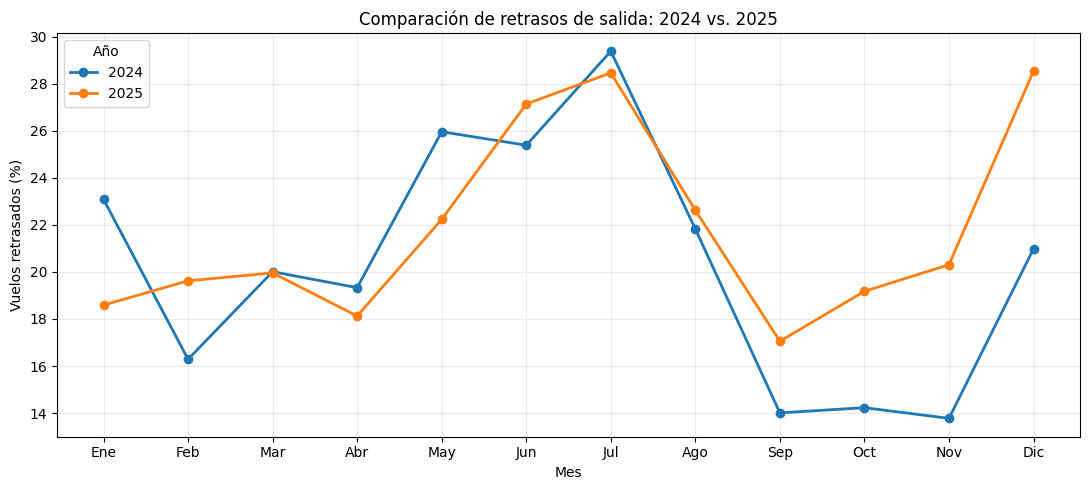

2024: mayor tasa en Jul (29.38%)
2025: mayor tasa en Dic (28.53%)


In [11]:

# ============================================================
# CELDA 6. COMPARACIÓN DE RETRASOS ENTRE 2024 Y 2025
# ============================================================

# En esta parte analizamos si el porcentaje de vuelos
# retrasados cambia entre 2024 y 2025.
# También buscamos identificar patrones que se repitan
# en determinados meses del año.

# Agrupamos los vuelos por año y mes.
comparacion_anual = (
    eda.groupby(["year", "month"])
    .agg(
        total_vuelos=("delayed_15", "size"),
        vuelos_retrasados=("delayed_15", "sum"),
        tasa_retraso=("delayed_15", "mean")
    )
    .reset_index()
)

# Convertimos la tasa a porcentaje.
comparacion_anual["tasa_retraso_pct"] = (
    comparacion_anual["tasa_retraso"] * 100
)

# Organizamos los porcentajes en una tabla.
# Cada fila representa un mes y cada columna un año.
tabla_comparacion = comparacion_anual.pivot(
    index="month",
    columns="year",
    values="tasa_retraso_pct"
).reindex(range(1, 13))

# Agregamos los nombres de los meses.
tabla_comparacion.index = [
    month_labels[mes]
    for mes in tabla_comparacion.index
]

print("Comparación mensual de retrasos (%):")
display(tabla_comparacion.round(2))

# Creamos una gráfica de líneas para visualizar
# las diferencias entre ambos años.
plt.figure(figsize=(11, 5))

for anio in [2024, 2025]:
    if anio in comparacion_anual["year"].values:

        datos_anio = comparacion_anual[
            comparacion_anual["year"] == anio
        ].sort_values("month")

        plt.plot(
            datos_anio["month"],
            datos_anio["tasa_retraso_pct"],
            marker="o",
            linewidth=2,
            label=str(anio)
        )

plt.xticks(
    range(1, 13),
    [month_labels[mes] for mes in range(1, 13)]
)

plt.title("Comparación de retrasos de salida: 2024 vs. 2025")
plt.xlabel("Mes")
plt.ylabel("Vuelos retrasados (%)")
plt.legend(title="Año")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Identificamos el mes con mayor porcentaje de retrasos
# dentro de cada año.
for anio in [2024, 2025]:

    datos_anio = comparacion_anual[
        comparacion_anual["year"] == anio
    ]

    if not datos_anio.empty:

        mes_maximo = datos_anio.loc[
            datos_anio["tasa_retraso_pct"].idxmax()
        ]

        print(
            f"{anio}: mayor tasa en "
            f"{month_labels[int(mes_maximo['month'])]} "
            f"({mes_maximo['tasa_retraso_pct']:.2f}%)"
        )


### Observaciones: retrasos por mes

Al comparar los resultados de 2024 y 2025, podemos observar que julio fue uno de los meses con más retrasos en ambos años, alcanzando aproximadamente el 29%. Esto podría indicar que durante el verano existen factores que afectan la puntualidad de los vuelos. También destaca diciembre de 2025, con un porcentaje de retrasos considerablemente mayor al de diciembre de 2024. Aunque encontramos algunas similitudes, los patrones no fueron completamente iguales entre ambos años.

Retrasos por hora programada de salida:


,hora,total_vuelos,vuelos_retrasados,tasa_retraso_pct
0,00:00,187,42,22.46
1,01:00,68,4,5.88
2,02:00,35,13,37.14
3,03:00,13,3,23.08
4,04:00,9,3,33.33
5,05:00,3334,251,7.53
6,06:00,8231,673,8.18
7,07:00,8501,848,9.98
8,08:00,8160,912,11.18
9,09:00,6722,954,14.19


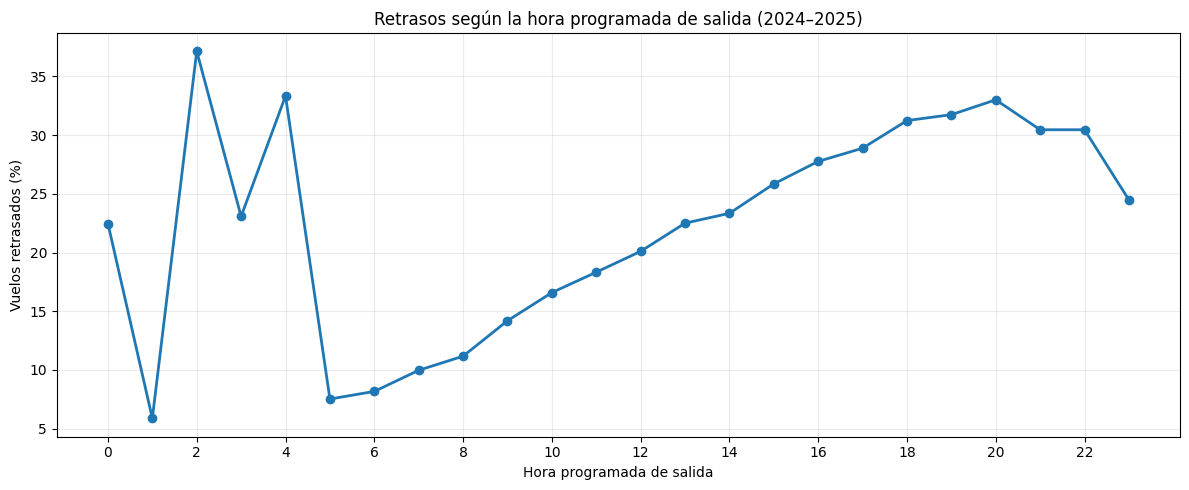

Hora con mayor tasa: 02:00 (37.14%)
Hora con menor tasa: 01:00 (5.88%)


In [13]:

# ============================================================
# CELDA 8. ANÁLISIS DE RETRASOS POR HORA DE SALIDA
# ============================================================

# Analizamos la relación entre la hora programada de salida
# y la proporción de vuelos que presentan retrasos.
#
# Utilizamos CRS_DEP_TIME porque representa el horario
# programado, conocido antes de que salga el vuelo.
# No utilizamos la hora real de salida como variable
# explicativa, porque todavía no se conocería al predecir.

# Agrupamos los vuelos por hora programada.
retrasos_hora = (
    eda.groupby("departure_hour")
    .agg(
        total_vuelos=("delayed_15", "size"),
        vuelos_retrasados=("delayed_15", "sum"),
        tasa_retraso=("delayed_15", "mean")
    )
    .reset_index()
    .sort_values("departure_hour")
)

# Convertimos las tasas a porcentajes.
retrasos_hora["tasa_retraso_pct"] = (
    retrasos_hora["tasa_retraso"] * 100
)

# Creamos etiquetas para mostrar las horas.
retrasos_hora["hora"] = (
    retrasos_hora["departure_hour"]
    .apply(lambda x: f"{x:02d}:00")
)

# Mostramos la tabla con los resultados.
print("Retrasos por hora programada de salida:")

display(
    retrasos_hora[
        [
            "hora",
            "total_vuelos",
            "vuelos_retrasados",
            "tasa_retraso_pct"
        ]
    ].round(2)
)

# Creamos una gráfica de líneas para observar
# cómo cambia la tasa de retrasos durante el día.
plt.figure(figsize=(12, 5))

plt.plot(
    retrasos_hora["departure_hour"],
    retrasos_hora["tasa_retraso_pct"],
    marker="o",
    linewidth=2
)

plt.title("Retrasos según la hora programada de salida (2024–2025)")
plt.xlabel("Hora programada de salida")
plt.ylabel("Vuelos retrasados (%)")

plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Identificamos la hora con mayor porcentaje de
# retrasos dentro de nuestra muestra.
hora_mayor = retrasos_hora.loc[
    retrasos_hora["tasa_retraso_pct"].idxmax()
]

hora_menor = retrasos_hora.loc[
    retrasos_hora["tasa_retraso_pct"].idxmin()
]

print(
    f"Hora con mayor tasa: {hora_mayor['hora']} "
    f"({hora_mayor['tasa_retraso_pct']:.2f}%)"
)

print(
    f"Hora con menor tasa: {hora_menor['hora']} "
    f"({hora_menor['tasa_retraso_pct']:.2f}%)"
)


### Observaciones: retrasos por hora programada

En esta gráfica observamos que los vuelos programados durante la mañana generalmente tienen menores porcentajes de retraso, mientras que durante la tarde y noche estos aumentan. Una posible explicación es que los retrasos operativos se vayan acumulando a lo largo del día. También encontramos variaciones importantes en la madrugada, aunque estos resultados deben interpretarse con cuidado porque hay menos vuelos registrados en esos horarios.


### Conclusión del análisis temporal

Con este análisis inicial identificamos que el mes y la hora programada de salida podrían influir en la probabilidad de que un vuelo se retrase. Los resultados muestran que existen diferencias entre temporadas y que los retrasos tienden a aumentar durante las últimas horas del día. Estas observaciones nos ayudarán a seleccionar variables para los modelos predictivos y serán revisadas posteriormente con el conjunto completo de datos en Databricks.